# SpecNova — AI-Assisted Molecular Identification from MS/MS Spectra







## 1. Project Overview

**The problem.** In tandem mass spectrometry (MS/MS), a molecule is broken into fragments and the instrument records a *spectrum*: a list of fragment masses (m/z) with intensities. Identifying an unknown compound from this fingerprint-like pattern is difficult because most molecules have no reference spectrum in any library.

**The approach.** SpecNova does not look for a matching reference spectrum. Instead, a pretrained neural network (**FPNet**) predicts the *molecular fingerprint* of the unknown compound directly from its spectrum. Candidate structures with the right mass are then ranked by how well their fingerprints agree with the prediction.

| | |
|---|---|
| **Input** | MS/MS peak list (m/z, intensity), precursor m/z, adduct (`[M+H]+`) |
| **Output** | Ranked candidate structures with formula, SMILES, ranking score and mass error |

## 2. How SpecNova Works

```
 MS/MS spectrum ─► Preprocessing ─► FPNet fingerprint ─► Candidate retrieval ─► Fingerprint matching ─► Ranked candidates
 (m/z, intensity)   peak cleaning     prediction          (precursor mass,       (score = f · logits)     (formula, SMILES,
                    + normalization   (10,226 bits)        10 ppm window)                                   score, ppm error)
```

1. **Preprocessing** – discards peaks above the precursor, normalizes intensities, keeps up to 160 strongest peaks (FPNet's own `prep_peaks`).
2. **FPNet inference** – a transformer encoder reads the peaks and outputs one logit per fingerprint bit.
3. **Candidate retrieval** – the neutral mass is derived from the precursor and used to select pool structures within **10 ppm**.
4. **Fingerprint matching and ranking** – each candidate's stored fingerprint *f* is scored as the dot product *f · logits*.
5. **Results** – candidates are sorted by that score.

## 3. Environment Setup
Essential imports, device selection, constants and Kaggle authentication.

In [1]:
import os, sys, shutil, getpass, subprocess, zipfile, warnings
from pathlib import Path

def _ensure(import_name, pip_name=None):
    try:
        __import__(import_name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name], check=True)

_ensure("rdkit"); _ensure("pyarrow")
if shutil.which("kaggle") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA_DIR = Path("/content/specnova_data") if Path("/content").exists() else Path("specnova_data")
PROTON_MASS = 1.0072764666          # [M+H]+ : neutral mass = precursor m/z - proton mass
MASS_TOL_PPM = 10.0                 # candidate retrieval window
SUPPORTED_ADDUCT = "[M+H]+"         # only positive-mode [M+H]+ is supported

MODELS_DS = "ahmedberatozer/casmi26-v4b-models"                          # FPNet code + checkpoint
POOL_DS   = "ahmedberatozer/casmi26-v2-pool"                             # candidate pool + fingerprints
NP_DS     = "dmitriigluzdov/casmi26-natural-product-knowledge-table"     # reference spectra for the demo

print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

# Kaggle authentication (token is never printed or stored in the notebook)
if not os.environ.get("KAGGLE_API_TOKEN") and not (Path.home() / ".kaggle" / "kaggle.json").exists():
    token = getpass.getpass("Enter your Kaggle API token: ").strip()
    if not token:
        raise ValueError("Kaggle API token is empty.")
    os.environ["KAGGLE_API_TOKEN"] = token

def fetch(dataset, remote_path, dest):
    """Download one file from a Kaggle dataset (skipped if already present) and return its local path."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    name = Path(remote_path).name
    found = list(dest.rglob(name))
    if found:
        return found[0]
    r = subprocess.run(["kaggle", "datasets", "download", "-d", dataset, "-f", remote_path, "-p", str(dest)],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"Download failed for {dataset}:{remote_path}\n{(r.stderr or r.stdout)[-800:]}")
    for z in dest.rglob(name + ".zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(z.parent)
        z.unlink()
    found = list(dest.rglob(name))
    if not found:
        raise FileNotFoundError(f"{name} not found after download.")
    return found[0]

Device: cuda (Tesla T4)
Enter your Kaggle API token: ··········


## 4. Model and Candidate Database Loading

* **FPNet** – pretrained transformer (8 layers, d = 512) predicting 10,226 fingerprint bits. The checkpoint is a public file loaded with PyTorch (`weights_only=False`, as the original code requires); only load checkpoints from sources you trust.
* **Candidate pool** – 710,701 structures (training structures plus COCONUT natural products) with metadata and fingerprints stored as packed bits (8 bits per byte) in FPNet's own bit layout.

In [4]:

# ============================================================
# SpecNova — Load FPNet Model and Dependencies
# ============================================================

from pathlib import Path
import sys
import importlib
import torch
import pandas as pd

# 1. Define model directory
V4B = DATA_DIR / "v4b"
CASMI_DIR = V4B / "code" / "casmi"

CASMI_DIR.mkdir(parents=True, exist_ok=True)

# 2. Download all required CASMI Python modules
required_files = [
    "chem.py",
    "fpnet.py",
    "fpnet6.py",
    "engine.py",
    "spectra.py",
    "traindata.py",
]

for filename in required_files:
    fetch(
        MODELS_DS,
        f"code/casmi/{filename}",
        CASMI_DIR
    )

# 3. Ensure CASMI is recognized as a Python package
(CASMI_DIR / "__init__.py").touch(exist_ok=True)

# 4. Add the correct package parent directory
PACKAGE_PARENT = CASMI_DIR.parent

if str(PACKAGE_PARENT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_PARENT))

# 5. Import modules
importlib.invalidate_caches()

for module_name in list(sys.modules):
    if module_name == "casmi" or module_name.startswith("casmi."):
        del sys.modules[module_name]

import casmi.chem as chem
import casmi.fpnet as fpnet

# 6. Load pretrained FPNet checkpoint
checkpoint = fetch(
    MODELS_DS,
    "fpnet_0.pt",
    V4B
)

model = fpnet.load_model(
    str(checkpoint),
    device=DEVICE
)

model.eval()

# 7. Display model information
model_info = pd.DataFrame({
    "Property": [
        "Checkpoint",
        "Device",
        "Fingerprint Bits",
        "Model Dimension",
        "Layers",
        "Attention Heads",
        "Parameters"
    ],
    "Value": [
        checkpoint.name,
        str(DEVICE),
        f"{model.nbits:,}",
        model.d,
        model.layers,
        model.heads,
        f"{sum(p.numel() for p in model.parameters()):,}"
    ]
})

display(model_info.style.hide(axis="index"))

print("\nFPNet loaded successfully!")
print("Model is ready for inference.")


Property,Value
Checkpoint,fpnet_0.pt
Device,cuda
Fingerprint Bits,"10,226"
Model Dimension,512
Layers,8
Attention Heads,8
Parameters,"49,686,780"



FPNet loaded successfully!
Model is ready for inference.


In [5]:
POOL_DIR = DATA_DIR / "pool"
pool_meta = pd.read_parquet(fetch(POOL_DS, "pool_meta.parquet", POOL_DIR))
fp_bits   = np.load(fetch(POOL_DS, "fp_bits.npy", POOL_DIR))
pool_fp   = np.load(fetch(POOL_DS, "pool_fp.npy", POOL_DIR), mmap_mode="r")     # packed uint8, memory-mapped
pool_masses = pool_meta["mass"].to_numpy(dtype=np.float64)                       # sorted ascending
pool_keys   = pool_meta["key"].astype(str).to_numpy()

# Consistency checks between model, metadata and fingerprints
assert len(pool_meta) == pool_fp.shape[0], "Pool metadata and fingerprint rows differ."
assert len(fp_bits) == model.nbits, "Model output size differs from the fingerprint bit list."
assert pool_fp.shape[1] * 8 >= model.nbits, "Packed fingerprints are too narrow."
assert np.all(np.diff(pool_masses) >= 0), "Pool masses must be sorted."

pd.DataFrame({
    "Property": ["Candidate structures", "Mass range (Da)", "Fingerprint bits per candidate"],
    "Value": [f"{len(pool_meta):,}", f"{pool_masses.min():.1f} – {pool_masses.max():.1f}", f"{model.nbits:,}"],
}).style.hide(axis="index")

Property,Value
Candidate structures,"710,701"
Mass range (Da),31.0 – 3399.6
Fingerprint bits per candidate,"10,226"


## 5. Spectrum Preprocessing

A spectrum is two aligned lists: fragment **m/z** values and their **intensities**. FPNet's existing `prep_peaks` function:

* removes peaks above *precursor m/z + 2* and non-positive m/z,
* scales intensities by the strongest peak and drops peaks below 0.1 % of it,
* keeps at most 160 peaks and sorts them by m/z,
* converts intensities to their square root.

The demonstration spectrum below is a reference record from the external evaluation file (GNPS, positive mode, `[M+H]+`).

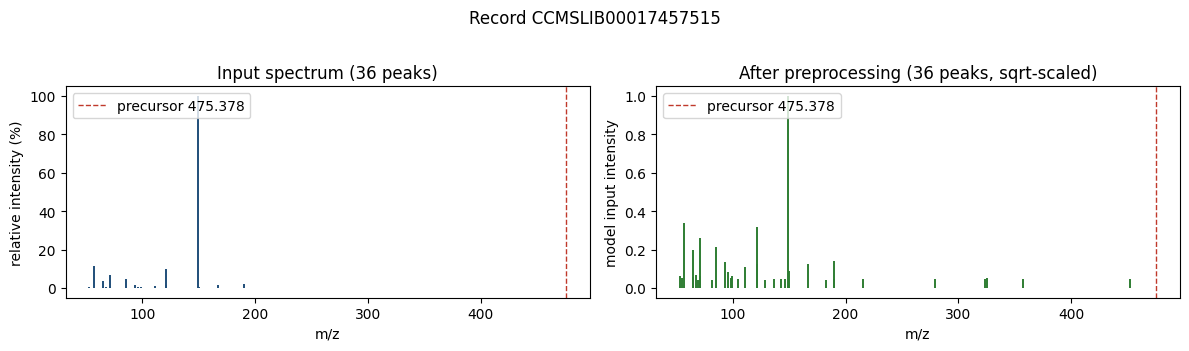

In [6]:
external = pd.read_parquet(fetch(NP_DS, "external_reference_spectra/external_delta.parquet", DATA_DIR / "external"))

def get_record(record_id):
    rows = external[external["record_id"].astype(str) == record_id]
    if rows.empty:
        raise KeyError(f"Record {record_id} not found.")
    return rows.iloc[0]

def clean_peaks(mz_values, intensities):
    mz_values = np.asarray(mz_values, dtype=np.float64)
    intensities = np.asarray(intensities, dtype=np.float64)
    if mz_values.shape != intensities.shape:
        raise ValueError("m/z and intensity lists have different lengths.")
    ok = np.isfinite(mz_values) & np.isfinite(intensities) & (mz_values > 0) & (intensities > 0)
    return mz_values[ok], intensities[ok]

def plot_preprocessing(raw_mz, raw_int, prep_mz, prep_int, precursor, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    axes[0].vlines(raw_mz, 0, 100 * raw_int / raw_int.max(), color="#1f4e79", linewidth=1.4)
    axes[0].set_title(f"Input spectrum ({len(raw_mz)} peaks)")
    axes[1].vlines(prep_mz, 0, prep_int, color="#2e7d32", linewidth=1.4)
    axes[1].set_title(f"After preprocessing ({len(prep_mz)} peaks, sqrt-scaled)")
    axes[0].set_ylabel("relative intensity (%)"); axes[1].set_ylabel("model input intensity")
    for ax in axes:
        ax.axvline(precursor, color="#c0392b", linestyle="--", linewidth=1, label=f"precursor {precursor:.3f}")
        ax.set_xlabel("m/z"); ax.legend(loc="upper left")
    fig.suptitle(title, y=1.02); fig.tight_layout(); plt.show()

DEMO_ID = "CCMSLIB00017457515"        # Diundecyl phthalate (known evaluation sample)
SECOND_ID = "CCMSLIB00017457536"      # Trimethyl citrate (secondary example)

demo = get_record(DEMO_ID)
raw_mz, raw_int = clean_peaks(demo["ms2_mzs"], demo["ms2_normalized_intensities"])
prep_mz, prep_int = fpnet.prep_peaks(raw_mz, raw_int, float(demo["precursor_mz"]))
plot_preprocessing(raw_mz, raw_int, prep_mz, prep_int, float(demo["precursor_mz"]), f"Record {DEMO_ID}")

## 6. AI Molecular Fingerprint Prediction

A **molecular fingerprint** is a long 0/1 vector in which each bit records whether a particular substructure pattern is present in a molecule. FPNet outputs one **logit** per bit (10,226 in total) for the spectrum it receives. A positive logit favours the bit being on.

These values are raw model outputs: they are **not calibrated probabilities or confidence values**. They are used directly in the candidate scoring step.

In [7]:
def build_item(prep_mz, prep_int, precursor_mz, adduct=SUPPORTED_ADDUCT, ce_ev=None):
    """Assemble the input dictionary expected by fpnet.collate (positive mode)."""
    ce_known = ce_ev is not None and np.isfinite(ce_ev)
    return {
        "mz": prep_mz, "it": prep_int, "prec": float(precursor_mz),
        "adduct_ix": chem.adduct_index(adduct),
        "ce": float(ce_ev) if ce_known else 0.0,
        "ce_known": 1.0 if ce_known else 0.0,
        "n_merged": 1, "mode": 1.0,
    }

def predict_logits(item, use_autocast=True):
    args = fpnet.collate([item], DEVICE)
    with torch.no_grad(), torch.autocast("cuda", dtype=fpnet.autocast_dtype(DEVICE),
                                         enabled=(DEVICE == "cuda" and use_autocast)):
        output = model(*args)
    return output[0].float().cpu().numpy()[0]

demo_logits = predict_logits(build_item(prep_mz, prep_int, demo["precursor_mz"], demo["adduct"]))
pd.DataFrame({
    "Quantity": ["Predicted fingerprint bits", "Bits with logit > 0", "Logit range"],
    "Value": [f"{len(demo_logits):,}", f"{int((demo_logits > 0).sum()):,}",
              f"{demo_logits.min():.1f} to {demo_logits.max():.1f}"],
}).style.hide(axis="index")

Quantity,Value
Predicted fingerprint bits,"10,226"
Bits with logit > 0,"1,499"
Logit range,-66.8 to 44.5


## 7. Candidate Retrieval and Ranking

1. **Mass filtering** – the neutral mass is `precursor m/z − 1.00728` (proton mass, `[M+H]+`). All pool structures within **±10 ppm** are retrieved.
2. **Fingerprint comparison** – the packed candidate fingerprints are unpacked to 10,226 bits.
3. **Ranking** – each candidate is scored with `score = f · logits` (the log-likelihood of the candidate's fingerprint under the model, up to a constant that does not depend on the candidate). Higher is better. Scores are only comparable within one query.

All of this is wrapped in one reusable function, `identify()`.

In [8]:
def candidate_window(precursor_mz, ppm=MASS_TOL_PPM):
    target = float(precursor_mz) - PROTON_MASS
    tol = target * ppm * 1e-6
    lo = np.searchsorted(pool_masses, target - tol, side="left")
    hi = np.searchsorted(pool_masses, target + tol, side="right")
    return target, np.arange(lo, hi)

def identify(precursor_mz, mz_values, intensities, adduct=SUPPORTED_ADDUCT, ce_ev=None,
             ppm=MASS_TOL_PPM, top_k=10, use_autocast=True):
    """Run the SpecNova pipeline on one MS/MS spectrum.

    Returns a dict with: n_candidates, ranked (all candidates, best first), top (first top_k rows),
    logits, prep_mz, prep_int, target_mass.
    """
    if adduct != SUPPORTED_ADDUCT:
        raise ValueError(f"Unsupported adduct '{adduct}'. Only {SUPPORTED_ADDUCT} (positive mode) is supported.")
    if not np.isfinite(precursor_mz) or precursor_mz <= PROTON_MASS:
        raise ValueError("Invalid precursor m/z.")

    mz_c, int_c = clean_peaks(mz_values, intensities)
    prep_mz, prep_int = fpnet.prep_peaks(mz_c, int_c, float(precursor_mz))
    if len(prep_mz) == 0:
        raise ValueError("No usable peaks after preprocessing.")

    logits = predict_logits(build_item(prep_mz, prep_int, precursor_mz, adduct, ce_ev), use_autocast)
    target, pids = candidate_window(precursor_mz, ppm)
    out = {"n_candidates": len(pids), "logits": logits, "prep_mz": prep_mz, "prep_int": prep_int,
           "target_mass": target, "ranked": pd.DataFrame(), "top": pd.DataFrame()}
    if len(pids) == 0:
        return out

    packed = np.asarray(pool_fp[pids])
    cand_fp = np.unpackbits(packed, axis=1)[:, :model.nbits].astype(np.float32)
    scores = cand_fp @ logits.astype(np.float32)
    order = np.argsort(-scores)
    sel = pids[order]
    meta_sel = pool_meta.iloc[sel]
    ranked = pd.DataFrame({
        "Rank": np.arange(1, len(sel) + 1),
        "Compound ID": meta_sel["key"].astype(str).to_numpy(),
        "Formula": meta_sel["formula"].to_numpy(),
        "SMILES": meta_sel["smiles"].to_numpy(),
        "Ranking score": scores[order],
        "Mass error (ppm)": (meta_sel["mass"].to_numpy() - target) / target * 1e6,
    })
    out["ranked"], out["top"] = ranked, ranked.head(top_k)
    return out

## 8. Main Demonstration — Molecular Identification

**Sample:** Diundecyl phthalate — GNPS record `CCMSLIB00017457515`.

This is a **known evaluation sample**: its true structure is known, so the notebook can check the result. The reference structure is *not* given to the pipeline — the model only receives the peak list, precursor m/z and adduct. The reference is used afterwards, solely to highlight the correct candidate.

The candidate pool stores InChIKey-based compound IDs, not names, so the compound name below comes from the reference record and is shown for evaluation only.

Item,Value
Record,CCMSLIB00017457515
Reference compound (evaluation only),Diundecyl phthalate
Precursor m/z,475.3780
Adduct / mode,[M+H]+ / positive
Input peaks → after preprocessing,36 → 36
Neutral mass (Da),474.37072
Candidates within 10 ppm,193


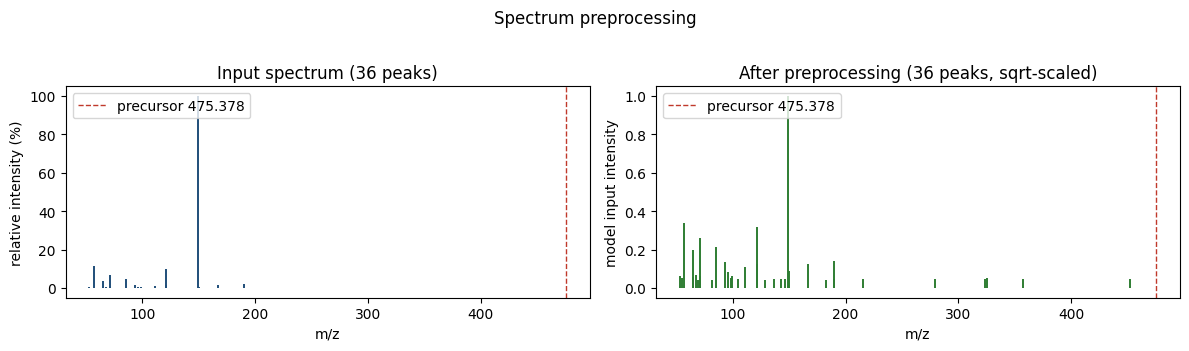

#### Top 5 candidates

Rank,Compound ID,Formula,SMILES,Ranking score,Mass error (ppm),Evaluation check
1,QQVHEQUEHCEAKS,C30H50O4,CCCCCCCCCCCOC(=O)c1ccccc1C(=O)OCCCCCCCCCCC,479.3,+0.39,✔ matches reference
2,LVFZGCKUCOADQM,C30H50O4,CCCCCCCC(CC)COC(=O)c1ccccc1C(=O)OCC(CC)CCCCCCC,432.8,+0.39,
3,PQLIXHHFGPDXGQ,C30H50O4,CCCCCCCCCCCCCCCCCCCCCOC(=O)C=Cc1ccc(O)c(O)c1,27.0,+0.39,
4,UBNJQWYYWIBSGN,C30H50O4,CCCCCCCCCCCCCCCCCCCCOC(=O)C=Cc1ccc(O)c(OC)c1,-9.7,+0.39,
5,YMMHDITUHQNNKU,C30H50O4,CC(=CCCC=C(C)CCC=C(C)CCC=C(CO)CO)CCC=C(C)CCC=C(CO)CO,-364.5,+0.39,


Reference structure rank: 1 of 193


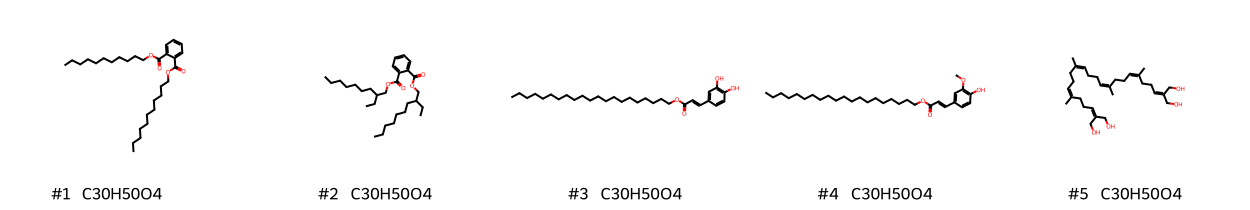

In [9]:
def show_identification(record_id, top_k=5, plots=True):
    row = get_record(record_id)
    true_key = str(row["original_inchikey"]).split("-")[0]

    result = identify(float(row["precursor_mz"]), row["ms2_mzs"], row["ms2_normalized_intensities"],
                      adduct=str(row["adduct"]), top_k=top_k)

    info = pd.DataFrame({
        "Item": ["Record", "Reference compound (evaluation only)", "Precursor m/z", "Adduct / mode",
                 "Input peaks → after preprocessing", "Neutral mass (Da)",
                 f"Candidates within {MASS_TOL_PPM:.0f} ppm"],
        "Value": [record_id, row["name"], f"{row['precursor_mz']:.4f}",
                  f"{row['adduct']} / {row['ionization_mode']}",
                  f"{len(row['ms2_mzs'])} → {len(result['prep_mz'])}",
                  f"{result['target_mass']:.5f}", f"{result['n_candidates']:,}"],
    })
    display(info.style.hide(axis="index"))

    if plots:
        mz_c, int_c = clean_peaks(row["ms2_mzs"], row["ms2_normalized_intensities"])
        plot_preprocessing(mz_c, int_c, result["prep_mz"], result["prep_int"],
                           float(row["precursor_mz"]), "Spectrum preprocessing")

    if result["n_candidates"] == 0:
        print("No candidates in the mass window."); return result

    top = result["top"].copy()
    top["Evaluation check"] = np.where(top["Compound ID"] == true_key, "✔ matches reference", "")
    shown = top[["Rank", "Compound ID", "Formula", "SMILES", "Ranking score", "Mass error (ppm)", "Evaluation check"]]
    highlight = lambda r: ["background-color:#d4edda;font-weight:600" if r["Evaluation check"] else ""] * len(r)
    display(Markdown(f"#### Top {top_k} candidates"))
    display(shown.style.apply(highlight, axis=1)
                 .format({"Ranking score": "{:.1f}", "Mass error (ppm)": "{:+.2f}"}).hide(axis="index"))

    ranked = result["ranked"]
    pos = np.where(ranked["Compound ID"].to_numpy() == true_key)[0]
    print(f"Reference structure rank: {pos[0] + 1} of {len(ranked)}" if len(pos)
          else "Reference structure is not among the retrieved candidates.")

    if plots:
        mols, legends = [], []
        for _, r in top.iterrows():
            m = Chem.MolFromSmiles(str(r["SMILES"]))
            if m is not None:
                mols.append(m)
                legends.append(f"#{r['Rank']}  {r['Formula']}" + (" ✔" if r["Evaluation check"] else ""))
        display(Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(250, 210), legends=legends))
    return result

demo_result = show_identification(DEMO_ID, top_k=5)

**What this shows.** From a peak list alone, SpecNova retrieved every pool structure with the right mass, scored each one against the fingerprint predicted by FPNet, and placed the correct compound first. The highlighted row is the structure that matches the reference record. This is one sample from the evaluation set (see Section 9 for the overall picture), not a general guarantee.

**Secondary example — Trimethyl citrate (`CCMSLIB00017457536`)**, also a known evaluation sample:

In [10]:
_ = show_identification(SECOND_ID, top_k=5, plots=False)

Item,Value
Record,CCMSLIB00017457536
Reference compound (evaluation only),Trimethyl citrate
Precursor m/z,235.0810
Adduct / mode,[M+H]+ / positive
Input peaks → after preprocessing,30 → 30
Neutral mass (Da),234.07372
Candidates within 10 ppm,17


#### Top 5 candidates

Rank,Compound ID,Formula,SMILES,Ranking score,Mass error (ppm),Evaluation check
1,HDDLVZWGOPWKFW,C9H14O7,COC(=O)CC(O)(CC(=O)OC)C(=O)OC,698.9,+0.98,✔ matches reference
2,VRBUFFFVTDWWMY,C9H14O7,CC(C)OC(=O)C(O)(CC(=O)O)CC(=O)O,304.1,+0.98,
3,SKHXHUZZFVMERR,C9H14O7,CC(C)OC(=O)CC(O)(CC(=O)O)C(=O)O,63.4,+0.98,
4,YNPKOQYWJZNZGP,C9H14O7,O=C(O)CCCCC(O)(CC(=O)O)C(=O)O,-199.4,+0.98,
5,MLKQIPXSLOCFKM,C9H14O7,CC(C(=O)O)C(O)(C(=O)O)C(C)(C)C(=O)O,-395.8,+0.98,


Reference structure rank: 1 of 17
